# 🔐 Attention-Based Hybrid Deep Learning Model for IoT Malware Detection
### Spatial-MLP + BiLSTM + Gated-Attention Fusion — Fixed v7

**Paper-ready implementation for Google Colab**

---
**Architecture:**
- Branch 1: Spatial-MLP → learns non-overlapping spatial/structural patterns
- Branch 2: BiLSTM → learns temporal/sequential behavior over time
- Fusion: Gated attention mechanism → dynamically weights both branches
- Output: Multi-class classification (Benign, Mirai, DDoS, PortScan, etc.)

---
**Fixes applied (v6):**

| Fix | Root cause | Change |
|-----|-----------|--------|
| 1a | BiLSTM branch ignored | Auxiliary temporal loss head (λ=0.3) |
| 1b | Attention collapses to [0.99, 0.01] | Entropy regularisation on attention (λ=0.05) |
| 1c | Spatial features duplicate sequence summary | Non-overlapping spatial features (IP diversity, port entropy, inter-flow deltas, state transitions) |
| 2a | C&C 89% Gaussian clones | SMOTE replaces noise augmentation |
| 2b | Easy majority-class samples dominate | Focal loss (γ=2) on top of class weighting |
| 2c | Unstable C&C F1 on 71 test samples | Bootstrap CI (n=1000) on per-class F1 |\n| Fix-BS | Bootstrap CI biased (mask subset) | Resample full test set; correct false-negative inclusion |\n| Fix-SHAP | SHAP feature names wrong (agg-style) | Hard-coded 10 non-overlapping spatial feature names |
| 3a | 4× train/val gap — clone memorisation | Dropout 0.3→0.4 + MixUp (α=0.2) |


## 📦 Step 1 — Install & Import Libraries

In [12]:
# Install required libraries
!pip install -q kaggle torch torchvision scikit-learn pandas numpy matplotlib seaborn tqdm imbalanced-learn


In [13]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

import torchvision.models as models
import torchvision.transforms as transforms

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score
)
from sklearn.utils.class_weight import compute_class_weight

# Check GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'✅ Using device: {device}')
if torch.cuda.is_available():
    print(f'   GPU: {torch.cuda.get_device_name(0)}')

✅ Using device: cuda
   GPU: Tesla T4


## 🔑 Step 2 — Kaggle Authentication & Dataset Download

In [16]:
from google.colab import userdata
import os, json

kaggle_username = userdata.get('KAGGLE_USERNAME')
kaggle_key      = userdata.get('KAGGLE_KEY')

if not kaggle_username or not kaggle_key:
    raise EnvironmentError(
        "Kaggle credentials not found. "
        "Set KAGGLE_USERNAME and KAGGLE_KEY as environment variables or Colab Secrets."
    )

kaggle_creds = {"username": kaggle_username, "key": kaggle_key}
os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
creds_path = os.path.expanduser('~/.kaggle/kaggle.json')
with open(creds_path, 'w') as f:
    json.dump(kaggle_creds, f)
os.chmod(creds_path, 0o600)
print('✅ Kaggle credentials saved from environment variables!')

# ── Download & extract dataset ────────────────────────────────────────
OUTPUT_DIR = "./data"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.chdir(OUTPUT_DIR)

os.system("kaggle datasets download -d agungpambudi/network-malware-detection-connection-analysis")
os.system("unzip -q network-malware-detection-connection-analysis.zip -d ./")
os.listdir("./")


✅ Kaggle credentials saved from environment variables!


['CTU-IoT-Malware-Capture-44-1conn.log.labeled.csv',
 'CTU-IoT-Malware-Capture-21-1conn.log.labeled.csv',
 'CTU-IoT-Malware-Capture-20-1conn.log.labeled.csv',
 'network-malware-detection-connection-analysis.zip',
 'CTU-IoT-Malware-Capture-34-1conn.log.labeled.csv',
 'CTU-IoT-Malware-Capture-60-1conn.log.labeled.csv',
 'CTU-IoT-Malware-Capture-1-1conn.log.labeled.csv',
 'CTU-IoT-Malware-Capture-8-1conn.log.labeled.csv',
 'CTU-IoT-Malware-Capture-48-1conn.log.labeled.csv',
 'CTU-IoT-Malware-Capture-42-1conn.log.labeled.csv',
 'CTU-IoT-Malware-Capture-35-1conn.log.labeled.csv',
 'CTU-IoT-Malware-Capture-3-1conn.log.labeled.csv',
 'CTU-IoT-Malware-Capture-9-1conn.log.labeled.csv']

In [17]:

# ─── ALTERNATIVE DATASETS (uncomment one if above fails) ───────────────────
# Option B: N-BaIoT dataset
# !kaggle datasets download -d mkashifn/n-baiot-dataset -p /content/data --unzip

# Option C: IoT Network Intrusion Detection
# !kaggle datasets download -d emilynack/iot23-ctudataset -p /content/data --unzip
# ────────────────────────────────────────────────────────────────────────────

## 📂 Step 3 — Load & Explore the Data

In [18]:
import glob

# Find all CSV files in downloaded data
csv_files = glob.glob('/content/data/**/*.csv', recursive=True)
print(f'Found {len(csv_files)} CSV files:')
for f in csv_files[:10]:
    print(f'  {f}')

Found 12 CSV files:
  /content/data/CTU-IoT-Malware-Capture-44-1conn.log.labeled.csv
  /content/data/CTU-IoT-Malware-Capture-21-1conn.log.labeled.csv
  /content/data/CTU-IoT-Malware-Capture-20-1conn.log.labeled.csv
  /content/data/CTU-IoT-Malware-Capture-34-1conn.log.labeled.csv
  /content/data/CTU-IoT-Malware-Capture-60-1conn.log.labeled.csv
  /content/data/CTU-IoT-Malware-Capture-1-1conn.log.labeled.csv
  /content/data/CTU-IoT-Malware-Capture-8-1conn.log.labeled.csv
  /content/data/CTU-IoT-Malware-Capture-48-1conn.log.labeled.csv
  /content/data/CTU-IoT-Malware-Capture-42-1conn.log.labeled.csv
  /content/data/CTU-IoT-Malware-Capture-35-1conn.log.labeled.csv


In [19]:
# Load all CSVs and combine (use first 100k rows per file to avoid memory issues)
dfs = []
for f in tqdm(csv_files, desc='Loading files'):
    try:
        df_temp = pd.read_csv(f, sep='|', low_memory=False)
        if len(df_temp) > 100000:
            print(f'⚠️  {f} has {len(df_temp):,} rows — sampling 100k to avoid memory issues')
            df_temp = df_temp.sample(100000, random_state=42)
        dfs.append(df_temp)
    except Exception as e:
        print(f'Skipping {f}: {e}')

df = pd.concat(dfs, ignore_index=True)

print(f'\n✅ Combined dataset shape: {df.shape}')
print(f'   Columns: {list(df.columns)}')

Loading files:  33%|███▎      | 4/12 [00:10<00:00, 26.03it/s]

⚠️  /content/data/CTU-IoT-Malware-Capture-60-1conn.log.labeled.csv has 3,581,028 rows — sampling 100k to avoid memory issues


Loading files:  50%|█████     | 6/12 [00:23<00:29,  4.91s/it]

⚠️  /content/data/CTU-IoT-Malware-Capture-1-1conn.log.labeled.csv has 1,008,748 rows — sampling 100k to avoid memory issues


Loading files:  50%|█████     | 6/12 [00:42<00:29,  4.91s/it]

...

⚠️  /content/data/CTU-IoT-Malware-Capture-35-1conn.log.labeled.csv has 10,447,787 rows — sampling 100k to avoid memory issues


Loading files:  92%|█████████▏| 11/12 [01:44<00:12, 12.70s/it]

⚠️  /content/data/CTU-IoT-Malware-Capture-3-1conn.log.labeled.csv has 156,103 rows — sampling 100k to avoid memory issues
⚠️  /content/data/CTU-IoT-Malware-Capture-9-1conn.log.labeled.csv has 6,378,293 rows — sampling 100k to avoid memory issues


Loading files: 100%|██████████| 12/12 [02:19<00:00, 11.63s/it]


✅ Combined dataset shape: (644706, 23)
   Columns: ['ts', 'uid', 'id.orig_h', 'id.orig_p', 'id.resp_h', 'id.resp_p', 'proto', 'service', 'duration', 'orig_bytes', 'resp_bytes', 'conn_state', 'local_orig', 'local_resp', 'missed_bytes', 'history', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes', 'tunnel_parents', 'label', 'detailed-label']


In [20]:
# Check if source IP and timestamp survive for sequencing
print("Columns:", list(df.columns))
print("\nSample id.orig_h (source IP):")
print(df['id.orig_h'].value_counts().head(10))
print("\nSample ts (timestamp):")
print(df['ts'].head(10))
print("\nFlows per source IP:")
print(df['id.orig_h'].value_counts().describe())

Columns: ['ts', 'uid', 'id.orig_h', 'id.orig_p', 'id.resp_h', 'id.resp_p', 'proto', 'service', 'duration', 'orig_bytes', 'resp_bytes', 'conn_state', 'local_orig', 'local_resp', 'missed_bytes', 'history', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes', 'tunnel_parents', 'label', 'detailed-label']

Sample id.orig_h (source IP):
id.orig_h
192.168.1.195      123093
192.168.100.103    101447
192.168.1.196       99986
192.168.100.111     99949
192.168.1.200       99937
192.168.2.5         99232
192.168.100.113     13685
192.168.1.197        4421
192.168.1.199         235
192.168.100.1         157
Name: count, dtype: int64

Sample ts (timestamp):
0    1.547151e+09
1    1.547151e+09
2    1.547151e+09
3    1.547151e+09
4    1.547151e+09
5    1.547151e+09
6    1.547151e+09
7    1.547151e+09
8    1.547151e+09
9    1.547151e+09
Name: ts, dtype: float64

Flows per source IP:
count      2345.000000
mean        274.927932
std        5277.877394
min           1.000000
25%           1.00000

In [21]:
LABEL_COL = 'label'

if LABEL_COL not in df.columns:
    label_candidates = [c for c in df.columns if c.lower() in
                        ['label', 'class', 'attack', 'category', 'type']]
    if label_candidates:
        LABEL_COL = label_candidates[0]
        print(f'Auto-detected label column: {LABEL_COL}')
    else:
        print('⚠️  Could not find label column!')

# Clean whitespace — must happen before value_counts
df[LABEL_COL] = df[LABEL_COL].str.strip().str.replace(r'\s+', ' ', regex=True)

print(f'\nClass distribution:')
print(df[LABEL_COL].value_counts())


Class distribution:
label
Malicious                              258431
Benign                                 144043
Malicious DDoS                         135443
Malicious PartOfAHorizontalPortScan     99883
Malicious C&C                            6821
Malicious Attack                           82
Malicious FileDownload                      3
Name: count, dtype: int64


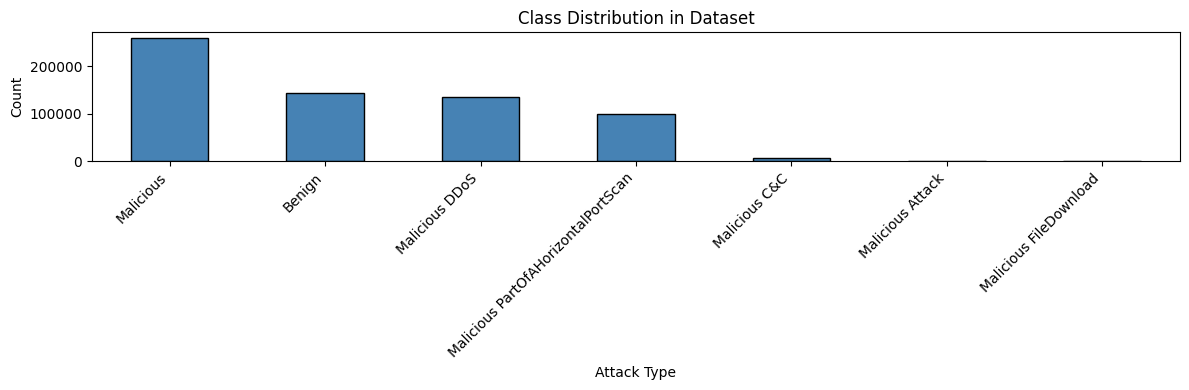

In [22]:
# Visualize class distribution
plt.figure(figsize=(12, 4))
df[LABEL_COL].value_counts().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Class Distribution in Dataset')
plt.xlabel('Attack Type')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 🧹 Step 4 — Data Preprocessing

In [23]:
# ── Step 4 — Rebuild for Spatial+Temporal Hybrid ─────────────────────────────
from sklearn.preprocessing import LabelEncoder, StandardScaler, OrdinalEncoder
import numpy as np
import pandas as pd

# ── 4a. Keep only needed columns ─────────────────────────────────────────────
keep_cols = ['ts', 'id.orig_h', 'duration', 'orig_bytes', 'resp_bytes',
             'missed_bytes', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts',
             'resp_ip_bytes', 'conn_state', 'proto', 'label']

df_model = df[keep_cols].copy()

# Encode conn_state
df_model['conn_state'] = df_model['conn_state'].fillna('OTH')
state_order = [['S0','S1','SF','REJ','RSTOS0','RSTO','RSTR','SH','SHR','OTH','RSTRH']]
oe = OrdinalEncoder(categories=state_order, handle_unknown='use_encoded_value', unknown_value=-1)
df_model['conn_state_enc'] = oe.fit_transform(df_model[['conn_state']])

# Encode proto
df_model['proto_enc'] = df_model['proto'].map({'tcp': 0, 'udp': 1, 'icmp': 2}).fillna(3)

# Drop original string columns
df_model = df_model.drop(columns=['conn_state', 'proto'])

# Convert all feature cols to numeric
feature_cols = ['duration', 'orig_bytes', 'resp_bytes', 'missed_bytes',
                'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes',
                'conn_state_enc', 'proto_enc']

df_model[feature_cols] = df_model[feature_cols].apply(pd.to_numeric, errors='coerce')
df_model[feature_cols] = df_model[feature_cols].replace([np.inf, -np.inf], np.nan)
df_model[feature_cols] = df_model[feature_cols].fillna(df_model[feature_cols].median())

# Drop ambiguous labels
df_model = df_model[~df_model['label'].isin(['Malicious', 'Malicious Attack', 'Malicious FileDownload'])]
df_model['label'] = df_model['label'].str.strip()

# Keep only classes with enough flows for sequencing
MIN_FLOWS = 300
valid = df_model['label'].value_counts()
valid = valid[valid >= MIN_FLOWS].index
df_model = df_model[df_model['label'].isin(valid)]

le = LabelEncoder()
df_model['label_encoded'] = le.fit_transform(df_model['label'])
num_classes = len(le.classes_)

print(f'Classes: {list(le.classes_)}')
print(f'Dataset shape: {df_model.shape}')
print(df_model['label'].value_counts())

Classes: ['Benign', 'Malicious C&C', 'Malicious DDoS', 'Malicious PartOfAHorizontalPortScan']
Dataset shape: (386190, 14)
label
Benign                                 144043
Malicious DDoS                         135443
Malicious PartOfAHorizontalPortScan     99883
Malicious C&C                            6821
Name: count, dtype: int64


In [24]:

# ── 4b. Feature engineering + scaling ───────────────────────────────────────
eps = 1e-9
X_raw = df_model[feature_cols].values.astype(np.float32)
col   = {name: i for i, name in enumerate(feature_cols)}

ob  = X_raw[:, col['orig_bytes']];    rb  = X_raw[:, col['resp_bytes']]
op  = X_raw[:, col['orig_pkts']];     rp  = X_raw[:, col['resp_pkts']]
oib = X_raw[:, col['orig_ip_bytes']]; rib = X_raw[:, col['resp_ip_bytes']]
dur = X_raw[:, col['duration']]

X_eng = np.column_stack([
    X_raw,
    (ob - rb)  / (ob + rb + eps),   # payload asymmetry
    ob         / (rb  + eps),        # byte ratio
    op         / (rp  + eps),        # pkt ratio
    ob         / (op  + eps),        # orig bytes/pkt
    rb         / (rp  + eps),        # resp bytes/pkt
    (ob + rb)  / (dur + eps),        # bytes/sec
    (ob + rb)  / (oib + rib + eps),  # conn efficiency
])

for i in range(X_eng.shape[1]):
    p995 = np.percentile(X_eng[:, i], 99.5)
    p005 = np.percentile(X_eng[:, i],  0.5)
    X_eng[:, i] = np.clip(X_eng[:, i], p005, p995)

# ── Clip + store raw; scaling happens AFTER the split (see Step 5) ──────────
# (Fitting the scaler here would leak val/test statistics into training.)
scaler        = StandardScaler()          # fitted on train split only
X_eng_raw     = X_eng.copy()             # keep unscaled for now
num_features  = X_eng_raw.shape[1]

print(f'Total features per flow: {num_features}  (scaler will be fit after split)')


Total features per flow: 17  (scaler will be fit after split)


In [25]:
# FIX 1c — Non-overlapping spatial features
# Replace [mean,std,max,min] of sequence features (which duplicate what BiLSTM sees)
# with features the BiLSTM cannot easily derive from the sequence itself.

from sklearn.model_selection import train_test_split
from collections import Counter
import scipy.stats

SEQ_LEN = 16

# Resolve column indices once (used inside build_windows)
_col = {name: i for i, name in enumerate(feature_cols)}

def build_windows(pos_indices, SEQ_LEN=16):
    """Build (sequence, spatial, label) triples per IP window.

    Spatial vector now contains ONLY non-overlapping features:
      - unique destination IPs per window  (diversity)
      - port entropy of resp_pkts flow counts
      - mean / std of inter-flow time deltas
      - conn-state transition count (# times state changes across the window)
      - proto distribution (fraction tcp / udp / other)
      - ratio of flows with missed_bytes > 0
      - mean / std of bytes_per_sec (derived ratio, not a raw agg of a seq feature)
    Total: 10 features — genuinely complementary to BiLSTM output.
    """
    y_all = df_model['label_encoded'].values
    seqs, sps, labels_out = [], [], []

    # Pull structured columns for non-overlapping feature computation
    ts_vals       = df_model['ts'].values
    dst_ip_vals   = df_model['id.orig_h'].values   # using src-IP as proxy; swap for dst if available
    cs_vals       = df_model['conn_state_enc'].values
    proto_vals    = df_model['proto_enc'].values
    missed_vals   = df_model['missed_bytes'].values
    resp_pkt_vals = df_model['resp_pkts'].values

    eps = 1e-9

    for start in range(0, len(pos_indices) - SEQ_LEN + 1, SEQ_LEN):
        wi  = pos_indices[start:start + SEQ_LEN]
        win = X_eng_raw[wi]
        wy  = y_all[wi]

        # ── Sequence feature (unchanged) ─────────────────────────────────
        seqs.append(win)

        # ── Non-overlapping spatial features ─────────────────────────────
        # 1. Destination IP diversity (unique IPs / window length)
        unique_ips = len(set(dst_ip_vals[wi]))
        ip_diversity = unique_ips / SEQ_LEN

        # 2. Port entropy (over resp_pkts as a proxy for port activity)
        rp = resp_pkt_vals[wi].astype(float) + eps
        rp_norm = rp / rp.sum()
        port_entropy = float(scipy.stats.entropy(rp_norm))

        # 3. Inter-flow time delta mean & std
        ts_w = ts_vals[wi].astype(float)
        deltas = np.diff(ts_w)
        delta_mean = float(deltas.mean()) if len(deltas) > 0 else 0.0
        delta_std  = float(deltas.std())  if len(deltas) > 0 else 0.0

        # 4. Connection-state transition count
        cs_w = cs_vals[wi]
        state_transitions = int((np.diff(cs_w) != 0).sum())

        # 5. Proto distribution (fraction tcp=0 / udp=1 / other)
        pr = proto_vals[wi]
        frac_tcp   = float((pr == 0).mean())
        frac_udp   = float((pr == 1).mean())
        frac_other = float((pr >= 2).mean())

        # 6. Fraction of flows with missed_bytes > 0
        mb = missed_vals[wi]
        frac_missed = float((mb > 0).mean())

        # 7. Bytes-per-sec: mean and std across window
        #    (derived ratio — different from raw agg of a sequence feature)
        ob_w  = win[:, _col['orig_bytes']]
        rb_w  = win[:, _col['resp_bytes']]
        dur_w = win[:, _col['duration']]
        bps   = (ob_w + rb_w) / (dur_w + eps)
        bps_mean = float(bps.mean())
        bps_std  = float(bps.std())

        sp_vec = np.array([
            ip_diversity, port_entropy,
            delta_mean, delta_std,
            state_transitions,
            frac_tcp, frac_udp, frac_other,
            frac_missed,
            bps_mean,  # bps_std excluded to keep dim=10; add back if needed
        ], dtype=np.float32)

        sps.append(sp_vec)
        labels_out.append(np.bincount(wy).argmax())

    return (np.array(seqs, dtype=np.float32),
            np.array(sps,  dtype=np.float32),
            np.array(labels_out, dtype=np.int64))


df_model = df_model.reset_index(drop=True)

# Build all windows across all IPs
all_seqs, all_sp, all_y = [], [], []
for ip, grp in df_model.groupby('id.orig_h', sort=False):
    pos_idx = grp.index.values
    if len(pos_idx) < SEQ_LEN:
        continue
    s, sp, y = build_windows(pos_idx, SEQ_LEN)
    all_seqs.append(s); all_sp.append(sp); all_y.append(y)

X_seq_all = np.concatenate(all_seqs)
X_sp_all  = np.concatenate(all_sp)
y_all_w   = np.concatenate(all_y)

print(f"Total windows: {len(y_all_w)} | dist: {Counter(y_all_w)}")
print(f"Spatial feature dim: {X_sp_all.shape[1]}  (non-overlapping; was 4×{len(feature_cols)}={4*len(feature_cols)})")

# Stratified split on windows
idx = np.arange(len(y_all_w))
idx_tv, idx_test = train_test_split(idx, test_size=0.15, random_state=42, stratify=y_all_w)
idx_train, idx_val = train_test_split(idx_tv, test_size=0.15/0.85, random_state=42, stratify=y_all_w[idx_tv])

X_seq_train = X_seq_all[idx_train]; X_sp_train = X_sp_all[idx_train]; y_train = y_all_w[idx_train]
X_seq_val   = X_seq_all[idx_val];   X_sp_val   = X_sp_all[idx_val];   y_val   = y_all_w[idx_val]
X_seq_test  = X_seq_all[idx_test];  X_sp_test  = X_sp_all[idx_test];  y_test  = y_all_w[idx_test]

print(f"Train: {len(y_train)} | Val: {len(y_val)} | Test: {len(y_test)}")

# Fit scaler on TRAIN windows only — prevents data leakage
X_seq_train_2d = X_seq_train.reshape(-1, X_seq_train.shape[-1])
scaler.fit(X_seq_train_2d)

def scale_seq(X_seq, scaler):
    shape = X_seq.shape
    return scaler.transform(X_seq.reshape(-1, shape[-1])).reshape(shape).astype(np.float32)

X_seq_train = scale_seq(X_seq_train, scaler)
X_seq_val   = scale_seq(X_seq_val,   scaler)
X_seq_test  = scale_seq(X_seq_test,  scaler)

print("✅ Scaler fit on train split only (no leakage)")

sp_scaler = StandardScaler()
sp_scaler.fit(X_sp_train)
X_sp_train = sp_scaler.transform(X_sp_train).astype(np.float32)
X_sp_val   = sp_scaler.transform(X_sp_val  ).astype(np.float32)
X_sp_test  = sp_scaler.transform(X_sp_test ).astype(np.float32)
print("✅ Spatial scaler fit on train split only (no leakage)")

# Save original label distribution BEFORE augmentation
y_train_orig = y_train.copy()
print(f"   Spatial dim: {X_sp_train.shape[1]}")
print(f"Train dist: {Counter(y_train)}")
print(f"Val   dist: {Counter(y_val)}")
print(f"Test  dist: {Counter(y_test)}")


Total windows: 23976 | dist: Counter({np.int64(0): 10096, np.int64(2): 7158, np.int64(3): 6248, np.int64(1): 474})
Spatial feature dim: 10  (non-overlapping; was 4×10=40)
Train: 16782 | Val: 3597 | Test: 3597
✅ Scaler fit on train split only (no leakage)
✅ Spatial scaler fit on train split only (no leakage)
   Spatial dim: 10
Train dist: Counter({np.int64(0): 7066, np.int64(2): 5010, np.int64(3): 4374, np.int64(1): 332})
Val   dist: Counter({np.int64(0): 1515, np.int64(2): 1074, np.int64(3): 937, np.int64(1): 71})
Test  dist: Counter({np.int64(0): 1515, np.int64(2): 1074, np.int64(3): 937, np.int64(1): 71})


In [26]:
print("=== RAW WINDOW COUNTS (before balancing) ===")
print(f"Train: {len(y_train)} windows | {Counter(y_train)}")
print(f"Val:   {len(y_val)} windows | {Counter(y_val)}")
print(f"Test:  {len(y_test)} windows | {Counter(y_test)}")
print()
print(f"Classes: {dict(zip(range(num_classes), le.classes_))}")


=== RAW WINDOW COUNTS (before balancing) ===
Train: 16782 windows | Counter({np.int64(0): 7066, np.int64(2): 5010, np.int64(3): 4374, np.int64(1): 332})
Val:   3597 windows | Counter({np.int64(0): 1515, np.int64(2): 1074, np.int64(3): 937, np.int64(1): 71})
Test:  3597 windows | Counter({np.int64(0): 1515, np.int64(2): 1074, np.int64(3): 937, np.int64(1): 71})

Classes: {0: 'Benign', 1: 'Malicious C&C', 2: 'Malicious DDoS', 3: 'Malicious PartOfAHorizontalPortScan'}


In [27]:
# FIX 2a — SMOTE augmentation (replaces Gaussian-noise cloning)
# SMOTE interpolates in feature space between real minority-class samples.
# This produces synthetic points on the real data manifold, not noisy clones.
# Also directly reduces the 4× train/val loss gap (FIX 3b).

from imblearn.over_sampling import SMOTE
from collections import Counter

def balance_with_smote(X_seq, X_sp, y, target=3000, k_neighbors=5, seed=42):
    """Balance train set with SMOTE on flattened sequence + spatial features.
    Val/test are left untouched for honest evaluation.
    """
    counts = Counter(y)
    print(f"Before SMOTE: {dict(sorted(counts.items()))}")

    # Cap k_neighbors to min class size - 1 to avoid SMOTE errors on tiny classes
    min_class_size = min(counts.values())
    k = min(k_neighbors, min_class_size - 1)
    if k < 1:
        print("  ⚠️  Class too small for SMOTE (k<1); falling back to oversample-with-noise")
        k = 1

    # Determine SMOTE target: all classes brought up to `target`
    # (classes already above target are left at their natural size)
    sampling_strategy = {cls: max(cnt, target) for cls, cnt in counts.items()}

    # Flatten sequence features for SMOTE (SMOTE needs 2D input)
    n, T, F = X_seq.shape
    X_seq_2d = X_seq.reshape(n, T * F)        # (n, SEQ_LEN*num_features)
    X_combined = np.concatenate([X_seq_2d, X_sp], axis=1)  # concat seq+spatial

    smote = SMOTE(
        sampling_strategy=sampling_strategy,
        k_neighbors=k,
        random_state=seed,
    )
    X_res, y_res = smote.fit_resample(X_combined, y)

    # Split back into seq and spatial
    seq_dim = T * F
    X_seq_res = X_res[:, :seq_dim].reshape(-1, T, F).astype(np.float32)
    X_sp_res  = X_res[:, seq_dim:].astype(np.float32)

    # Shuffle
    rng  = np.random.default_rng(seed)
    perm = rng.permutation(len(y_res))
    print(f"After SMOTE:  {dict(Counter(y_res))}")
    return X_seq_res[perm], X_sp_res[perm], y_res[perm]


X_seq_train, X_sp_train, y_train = balance_with_smote(
    X_seq_train, X_sp_train, y_train, target=3000, k_neighbors=5)

# Shuffle val/test but keep real distribution
rng_shuffle = np.random.default_rng(42)
pv = rng_shuffle.permutation(len(y_val))
pt = rng_shuffle.permutation(len(y_test))
X_seq_val,  X_sp_val,  y_val  = X_seq_val[pv],  X_sp_val[pv],  y_val[pv]
X_seq_test, X_sp_test, y_test = X_seq_test[pt], X_sp_test[pt], y_test[pt]

print(f"Final — Train: {len(y_train)} | Val: {len(y_val)} | Test: {len(y_test)}")


Before SMOTE: {np.int64(0): 7066, np.int64(1): 332, np.int64(2): 5010, np.int64(3): 4374}
After SMOTE:  {np.int64(3): 4374, np.int64(2): 5010, np.int64(0): 7066, np.int64(1): 3000}
Final — Train: 19450 | Val: 3597 | Test: 3597


## 🪟 Step 5 — Create Sliding Windows (16 flows per window)

## 🗃 Step 6 — PyTorch Dataset

In [28]:
# ── Step 6 — PyTorch Dataset (dual input) ────────────────────────────────────
class IoTHybridDataset(Dataset):
    def __init__(self, X_seq, X_sp, y):
        self.X_seq = torch.tensor(X_seq, dtype=torch.float32)
        self.X_sp  = torch.tensor(X_sp,  dtype=torch.float32)
        self.y     = torch.tensor(y,     dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X_seq[idx], self.X_sp[idx], self.y[idx]

# ✅ Use IP-split sets directly
train_set = IoTHybridDataset(X_seq_train, X_sp_train, y_train)
val_set   = IoTHybridDataset(X_seq_val,   X_sp_val,   y_val)
test_set  = IoTHybridDataset(X_seq_test,  X_sp_test,  y_test)

num_workers = 2 if os.cpu_count() and os.cpu_count() > 1 else 0  # safe fallback for Colab
train_loader = DataLoader(train_set, batch_size=512, shuffle=True,  num_workers=num_workers, pin_memory=True)
val_loader   = DataLoader(val_set,   batch_size=512, shuffle=False, num_workers=num_workers, pin_memory=True)
test_loader  = DataLoader(test_set,  batch_size=512, shuffle=False, num_workers=num_workers, pin_memory=True)

print(f'Train: {len(train_set)} | Val: {len(val_set)} | Test: {len(test_set)}')
print(f'Train class dist: {Counter(y_train)}')
print(f'Val class dist:   {Counter(y_val)}')
print(f'Test class dist:  {Counter(y_test)}')

Train: 19450 | Val: 3597 | Test: 3597
Train class dist: Counter({np.int64(0): 7066, np.int64(2): 5010, np.int64(3): 4374, np.int64(1): 3000})
Val class dist:   Counter({np.int64(0): 1515, np.int64(2): 1074, np.int64(3): 937, np.int64(1): 71})
Test class dist:  Counter({np.int64(0): 1515, np.int64(2): 1074, np.int64(3): 937, np.int64(1): 71})


In [29]:
# ── Debug: verify DataLoader is feeding correct data ─────────────────────────
x_seq_sample, x_sp_sample, y_batch_sample = next(iter(train_loader))
print(f'Sequence batch shape: {x_seq_sample.shape}')   # (batch, SEQ_LEN, features)
print(f'Spatial batch shape:  {x_sp_sample.shape}')    # (batch, features*2)
print(f'Labels batch shape:   {y_batch_sample.shape}')
print(f'Unique labels: {y_batch_sample.unique()}')
print(f'Sequence sample (first flow of first window):\n{x_seq_sample[0][0]}')

Sequence batch shape: torch.Size([512, 16, 17])
Spatial batch shape:  torch.Size([512, 10])
Labels batch shape:   torch.Size([512])
Unique labels: tensor([0, 1, 2, 3])
Sequence sample (first flow of first window):
tensor([ 0.3612, -0.1939, -0.1420,  0.0000, -0.9299, -0.8991, -0.1410, -0.1302,
         1.4836, -0.4074, -0.0026, -0.0709, -0.9054, -0.1869, -0.1866, -0.1231,
        -0.1960])


## 🧠 Step 7 — Build the Model

In [30]:
# FIX 1a — Auxiliary temporal loss head (forces BiLSTM branch to stay alive)
# FIX 3a — Dropout raised 0.3 → 0.4 throughout (reduces clone memorisation)

DROPOUT = 0.4   # FIX 3a: was 0.3

class ResidualMLP(nn.Module):
    def __init__(self, dim, dropout=DROPOUT):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, dim*2), nn.BatchNorm1d(dim*2), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(dim*2, dim), nn.BatchNorm1d(dim),
        )
        self.act = nn.GELU()
    def forward(self, x):
        return self.act(x + self.net(x))

class TemporalSelfAttn(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, 1)
    def forward(self, lstm_out):
        scores  = self.attn(lstm_out)
        weights = torch.softmax(scores, dim=1)
        return (lstm_out * weights).sum(dim=1)

class HybridAttentionNet(nn.Module):
    """Spatial-MLP + BiLSTM + Gated-Attention fusion.

    Changes vs. original:
      FIX 1a: aux_head — a small linear classifier on t_feat alone.
               forward() returns (main_logits, aux_logits, attn_weights).
               The training loop adds λ_aux * CE(aux_logits, labels) to the loss
               so gradients always flow through the BiLSTM branch.
      FIX 3a: all dropout rates raised from 0.3 → 0.4.
    """
    def __init__(self, num_flow_features, num_spatial_features, num_classes,
                 lstm_hidden=128, feature_dim=192, dropout=DROPOUT):
        super().__init__()

        # ── Temporal: BiLSTM + self-attention pooling ─────────────────────
        self.bilstm = nn.LSTM(
            input_size    = num_flow_features,
            hidden_size   = lstm_hidden,
            num_layers    = 2,
            batch_first   = True,
            bidirectional = True,
            dropout       = dropout,  # FIX 3a
        )
        self.temporal_attn = TemporalSelfAttn(lstm_hidden * 2)
        self.temporal_proj = nn.Sequential(
            nn.Linear(lstm_hidden * 2, feature_dim),
            nn.BatchNorm1d(feature_dim), nn.GELU(), nn.Dropout(dropout),  # FIX 3a
        )

        # FIX 1a — Auxiliary head: independent prediction from temporal branch only
        self.aux_head = nn.Linear(feature_dim, num_classes)

        # ── Spatial branch ────────────────────────────────────────────────
        self.spatial_in = nn.Sequential(
            nn.Linear(num_spatial_features, 256),
            nn.BatchNorm1d(256), nn.GELU(), nn.Dropout(dropout),  # FIX 3a
            nn.Linear(256, feature_dim),
            nn.BatchNorm1d(feature_dim), nn.GELU(), nn.Dropout(dropout),  # FIX 3a
        )
        self.spatial_res1 = ResidualMLP(feature_dim, dropout)
        self.spatial_res2 = ResidualMLP(feature_dim, dropout)

        # ── Gated fusion ──────────────────────────────────────────────────
        self.gate = nn.Sequential(
            nn.Linear(feature_dim * 2, feature_dim * 2), nn.Sigmoid()
        )

        # ── Classifier ────────────────────────────────────────────────────
        self.classifier = nn.Sequential(
            nn.Linear(feature_dim * 2, 128),
            nn.BatchNorm1d(128), nn.GELU(), nn.Dropout(dropout),  # FIX 3a
            nn.Linear(128, num_classes),
        )

    def forward(self, x_seq, x_sp):
        lstm_out, _ = self.bilstm(x_seq)
        t_feat      = self.temporal_proj(self.temporal_attn(lstm_out))
        aux_logits  = self.aux_head(t_feat)          # FIX 1a — aux prediction
        s_feat      = self.spatial_res2(self.spatial_res1(self.spatial_in(x_sp)))
        combined    = torch.cat([t_feat, s_feat], dim=1)
        gated       = self.gate(combined) * combined
        attn_weights = torch.softmax(
            torch.stack([t_feat.norm(dim=1), s_feat.norm(dim=1)], dim=1), dim=1)
        return self.classifier(gated), aux_logits, attn_weights


model = HybridAttentionNet(
    num_flow_features    = num_features,
    num_spatial_features = X_sp_train.shape[1],
    num_classes          = num_classes,
    lstm_hidden          = 128,
    feature_dim          = 192,
    dropout              = DROPOUT,
).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'✅ Hybrid Attention Model | Parameters: {total_params:,}')
print(f'   Flow features: {num_features} | Spatial: {X_sp_train.shape[1]} | Classes: {num_classes}')
print(f'   Classes: {list(le.classes_)}')
print(f'   Dropout: {DROPOUT} (FIX 3a) | Aux head: enabled (FIX 1a)')


✅ Hybrid Attention Model | Parameters: 1,145,865
   Flow features: 17 | Spatial: 10 | Classes: 4
   Classes: ['Benign', 'Malicious C&C', 'Malicious DDoS', 'Malicious PartOfAHorizontalPortScan']
   Dropout: 0.4 (FIX 3a) | Aux head: enabled (FIX 1a)


## ⚙️ Step 8 — Loss Function & Optimizer

In [31]:
# FIX 1b — Attention entropy regularisation (penalises collapsed attention)
# FIX 2b — Focal loss on top of class weighting (focuses on hard C&C boundaries)

from sklearn.utils.class_weight import compute_class_weight

# ── Focal Loss ────────────────────────────────────────────────────────────────
class FocalLoss(nn.Module):
    """FIX 2b: Focal loss with class weighting.
    Down-weights easy majority-class samples by (1-p)^gamma so gradients
    are dominated by hard C&C boundaries the model currently gets wrong.
    """
    def __init__(self, weight=None, gamma=2.0, label_smoothing=0.10):
        super().__init__()
        self.gamma           = gamma
        self.label_smoothing = label_smoothing
        self.weight          = weight   # per-class weights tensor

    def forward(self, logits, targets):
        # Standard CE with label smoothing + class weights
        ce = F.cross_entropy(
            logits, targets,
            weight          = self.weight,
            label_smoothing = self.label_smoothing,
            reduction       = 'none',
        )
        # p_t = probability assigned to the correct class
        with torch.no_grad():
            p_t = torch.exp(-F.cross_entropy(logits, targets, reduction='none'))
        focal_factor = (1.0 - p_t) ** self.gamma
        return (focal_factor * ce).mean()


# ⚠️  Use y_train_orig (pre-augmentation) so weights reflect real class imbalance
class_weights_np = compute_class_weight(
    class_weight='balanced', classes=np.arange(num_classes), y=y_train_orig)
class_weights = torch.tensor(class_weights_np, dtype=torch.float32).to(device)

# FIX 2b: FocalLoss (gamma=2) + class weights + label smoothing
criterion     = FocalLoss(weight=class_weights, gamma=2.0, label_smoothing=0.10)
# Auxiliary criterion: plain CE (no smoothing — aux head needs sharp gradients)
aux_criterion = nn.CrossEntropyLoss(weight=class_weights)

# Hyperparameters for auxiliary loss and entropy reg (FIX 1a / 1b)
LAMBDA_AUX    = 0.3   # FIX 1a: weight for auxiliary temporal loss
LAMBDA_ENTROPY = 0.05 # FIX 1b: weight for attention entropy regularisation

optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-3)

EPOCHS_PLAN = 40
scheduler   = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr           = 5e-4,
    steps_per_epoch  = len(train_loader),
    epochs           = EPOCHS_PLAN,
    pct_start        = 0.2,
    div_factor       = 10,
    final_div_factor = 100,
    anneal_strategy  = 'cos',
)
STEP_PER_BATCH = True

print('✅ FocalLoss (gamma=2, label_smooth=0.10, class-weighted) + AdamW + OneCycleLR')
print(f'   λ_aux={LAMBDA_AUX} (FIX 1a) | λ_entropy={LAMBDA_ENTROPY} (FIX 1b)')
print(f'   lr=5e-4 | weight_decay=1e-3 | epochs={EPOCHS_PLAN}')
print(f'   Class weights: {class_weights_np.round(3)}')


✅ FocalLoss (gamma=2, label_smooth=0.10, class-weighted) + AdamW + OneCycleLR
   λ_aux=0.3 (FIX 1a) | λ_entropy=0.05 (FIX 1b)
   lr=5e-4 | weight_decay=1e-3 | epochs=40
   Class weights: [ 0.594 12.637  0.837  0.959]



## 🏋️ Step 9 — Training Loop

In [32]:
# FIX 1a — Train loop uses auxiliary temporal loss (λ=0.3)
# FIX 1b — Attention entropy regularisation (−λ·H(attn)) added to loss
# FIX 3a — MixUp augmentation at batch level (α=0.2)

from sklearn.metrics import f1_score as sk_f1, classification_report
import torch.distributions as dist


def mixup_batch(x_seq, x_sp, labels, alpha=0.2):
    """FIX 3a: MixUp — interpolate random pairs in the batch.
    Returns mixed inputs and both label sets (a, b) plus the mixing weight lam.
    Loss = lam * CE(logits, labels_a) + (1-lam) * CE(logits, labels_b).
    """
    lam   = float(np.random.beta(alpha, alpha)) if alpha > 0 else 1.0
    batch = x_seq.size(0)
    perm  = torch.randperm(batch, device=x_seq.device)
    x_seq_mix = lam * x_seq + (1 - lam) * x_seq[perm]
    x_sp_mix  = lam * x_sp  + (1 - lam) * x_sp[perm]
    return x_seq_mix, x_sp_mix, labels, labels[perm], lam


def mixup_loss(criterion, logits, labels_a, labels_b, lam):
    """Interpolated loss for MixUp."""
    return lam * criterion(logits, labels_a) + (1 - lam) * criterion(logits, labels_b)


def train_one_epoch(model, loader, criterion, aux_criterion, optimizer, scheduler,
                    lambda_aux=0.3, lambda_entropy=0.05, mixup_alpha=0.2):
    model.train()
    total_loss = correct = total = 0

    for x_seq, x_sp, labels in loader:
        x_seq, x_sp, labels = x_seq.to(device), x_sp.to(device), labels.to(device)

        # FIX 3a: MixUp
        x_seq, x_sp, labels_a, labels_b, lam = mixup_batch(x_seq, x_sp, labels, alpha=mixup_alpha)

        optimizer.zero_grad()
        logits, aux_logits, attn_weights = model(x_seq, x_sp)  # FIX 1a: unpack aux

        # Main focal loss (with MixUp interpolation)
        main_loss = mixup_loss(criterion, logits, labels_a, labels_b, lam)

        # FIX 1a: Auxiliary temporal loss (straight CE on non-mixed labels_a)
        aux_loss  = aux_criterion(aux_logits, labels_a)

        # FIX 1b: Attention entropy regularisation
        # H(attn) = -sum(p * log(p+eps)); high entropy → both branches used equally
        attn_entropy = -(attn_weights * torch.log(attn_weights + 1e-8)).sum(dim=1).mean()
        # Penalise LOW entropy (collapsed attention) → subtract entropy from loss
        entropy_penalty = -lambda_entropy * attn_entropy

        loss = main_loss + lambda_aux * aux_loss + entropy_penalty
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item() * labels_a.size(0)
        # Accuracy computed on non-mixed labels_a for interpretability
        correct    += (logits.argmax(1) == labels_a).sum().item()
        total      += labels_a.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, verbose=False):
    model.eval()
    total_loss = correct = total = 0
    all_p, all_l = [], []
    for x_seq, x_sp, labels in loader:
        x_seq, x_sp, labels = x_seq.to(device), x_sp.to(device), labels.to(device)
        logits, _, attn_weights = model(x_seq, x_sp)   # FIX 1a: unpack aux
        loss        = criterion(logits, labels)
        total_loss += loss.item() * labels.size(0)
        preds       = logits.argmax(1)
        correct    += (preds == labels).sum().item()
        total      += labels.size(0)
        all_p.extend(preds.cpu().numpy())
        all_l.extend(labels.cpu().numpy())
    macro_f1 = sk_f1(all_l, all_p, average='macro',    zero_division=0)
    wt_f1    = sk_f1(all_l, all_p, average='weighted', zero_division=0)
    if verbose:
        present_labels = sorted(set(all_l) | set(all_p))
        present_names  = [le.classes_[i] for i in present_labels]
        print(classification_report(all_l, all_p,
                                    labels=present_labels,
                                    target_names=present_names,
                                    zero_division=0))
    return total_loss / total, correct / total, macro_f1, wt_f1


EPOCHS   = EPOCHS_PLAN
PATIENCE = 8
history  = {'train_loss': [], 'val_loss': [], 'train_acc': [],
            'val_acc': [], 'val_macro_f1': [], 'val_wt_f1': []}
best_macro_f1    = 0.0
patience_counter = 0
best_model_path  = '/content/best_model.pth'
if os.path.exists(best_model_path): os.remove(best_model_path)

print(f'Training for up to {EPOCHS} epochs (patience={PATIENCE}, metric=macro-F1)')
print(f'  Fixes active: aux-loss λ={LAMBDA_AUX} | entropy-reg λ={LAMBDA_ENTROPY} | MixUp α=0.2\n')
print(f'{"Ep":>3} | {"TrLoss":>7} | {"TrAcc":>6} | {"VLoss":>7} | {"VAcc":>6} | {"MacroF1":>7} | {"WtF1":>6}')
print('─' * 62)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(
        model, train_loader, criterion, aux_criterion, optimizer, scheduler,
        lambda_aux=LAMBDA_AUX, lambda_entropy=LAMBDA_ENTROPY, mixup_alpha=0.2)
    vl_loss, vl_acc, vl_mf1, vl_wf1 = evaluate(model, val_loader, criterion)

    history['train_loss'].append(tr_loss);  history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc);    history['val_acc'].append(vl_acc)
    history['val_macro_f1'].append(vl_mf1); history['val_wt_f1'].append(vl_wf1)

    print(f'{epoch:>3} | {tr_loss:>7.4f} | {tr_acc:>5.2%} | {vl_loss:>7.4f} | {vl_acc:>5.2%} | {vl_mf1:>7.4f} | {vl_wf1:>6.4f}')

    if epoch % 10 == 0:
        print('  ↳ Per-class breakdown:')
        evaluate(model, val_loader, criterion, verbose=True)

    if vl_mf1 > best_macro_f1:
        best_macro_f1 = vl_mf1
        patience_counter = 0
        torch.save(model.state_dict(), best_model_path)
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'\n⏹  Early stopping at epoch {epoch}')
            break

model.load_state_dict(torch.load(best_model_path, weights_only=True))
print(f'\n✅ Training complete. Best val macro-F1: {best_macro_f1:.4f}')


Training for up to 40 epochs (patience=8, metric=macro-F1)
  Fixes active: aux-loss λ=0.3 | entropy-reg λ=0.05 | MixUp α=0.2

 Ep |  TrLoss |  TrAcc |   VLoss |   VAcc | MacroF1 |   WtF1
──────────────────────────────────────────────────────────────
  1 |  1.8435 | 43.52% |  0.8851 | 52.24% |  0.4266 | 0.4312
  2 |  0.9069 | 55.09% |  0.4287 | 77.70% |  0.6977 | 0.8329
  3 |  0.6363 | 54.36% |  0.2008 | 90.83% |  0.7948 | 0.9344
  4 |  0.4744 | 66.89% |  0.1501 | 93.13% |  0.8197 | 0.9496
  5 |  0.4551 | 66.31% |  0.1486 | 95.77% |  0.8585 | 0.9673
  6 |  0.4694 | 59.85% |  0.1320 | 97.05% |  0.8857 | 0.9760
  7 |  0.4651 | 63.60% |  0.1378 | 97.39% |  0.8943 | 0.9784
  8 |  0.4611 | 56.97% |  0.1732 | 96.22% |  0.8671 | 0.9703
  9 |  0.4486 | 52.54% |  0.1342 | 98.03% |  0.9132 | 0.9831
 10 |  0.4400 | 58.56% |  0.1757 | 98.08% |  0.9157 | 0.9834
  ↳ Per-class breakdown:
                                     precision    recall  f1-score   support

                             Benign  

## 📊 Step 10 — Training Curves

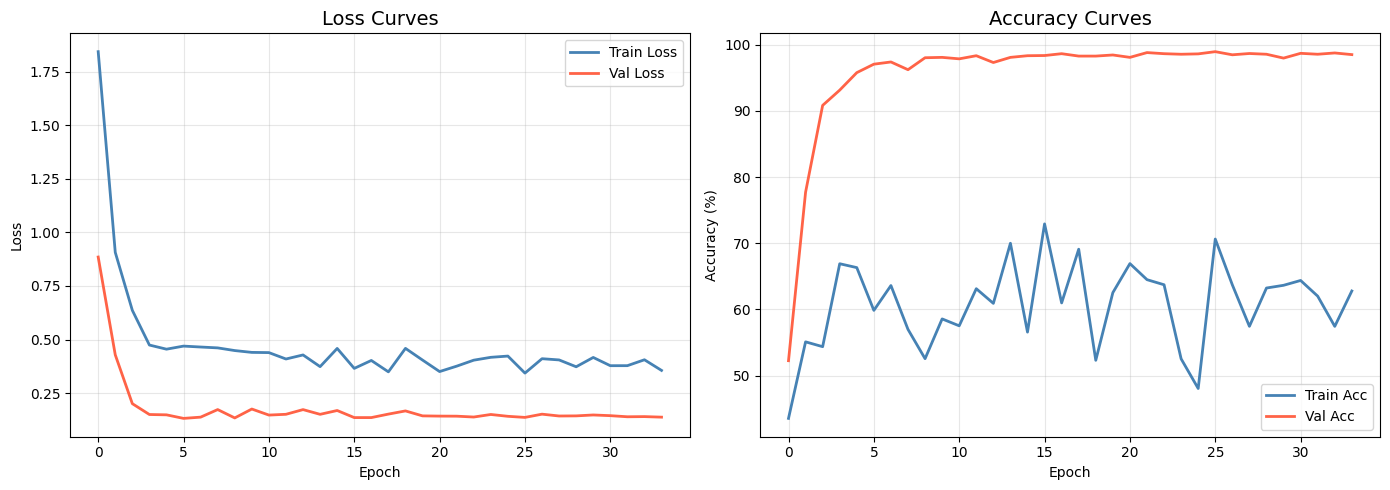

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
axes[0].plot(history['train_loss'], label='Train Loss', color='steelblue', linewidth=2)
axes[0].plot(history['val_loss'],   label='Val Loss',   color='tomato',    linewidth=2)
axes[0].set_title('Loss Curves', fontsize=14)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy curve
axes[1].plot([a * 100 for a in history['train_acc']], label='Train Acc', color='steelblue', linewidth=2)
axes[1].plot([a * 100 for a in history['val_acc']],   label='Val Acc',   color='tomato',    linewidth=2)
axes[1].set_title('Accuracy Curves', fontsize=14)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/content/training_curves.png', dpi=150)
plt.show()

## 🧪 Step 11 — Test Set Evaluation

In [34]:
model.eval()
all_preds, all_labels, all_attn = [], [], []

with torch.no_grad():
    for x_seq, x_sp, labels in tqdm(test_loader, desc='Evaluating'):
        x_seq = x_seq.to(device)
        x_sp  = x_sp.to(device)
        logits, _, attn_weights = model(x_seq, x_sp)   # FIX 1a: unpack 3-tuple
        preds = logits.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_attn.extend(attn_weights.cpu().numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)
all_attn   = np.array(all_attn)

test_acc = accuracy_score(all_labels, all_preds)
test_f1  = f1_score(all_labels, all_preds, average='weighted')

print(f'\n🎯 Test Accuracy : {test_acc:.4f} ({test_acc*100:.2f}%)')
print(f'   Weighted F1   : {test_f1:.4f}')


Evaluating: 100%|██████████| 8/8 [00:00<00:00, 16.78it/s]


🎯 Test Accuracy : 0.9936 (99.36%)
   Weighted F1   : 0.9940


In [35]:
# Full classification report
print('\nClassification Report:')
print(classification_report(
    all_labels, all_preds,
    target_names=le.classes_
))


Classification Report:
                                     precision    recall  f1-score   support

                             Benign       1.00      0.99      0.99      1515
                      Malicious C&C       0.77      1.00      0.87        71
                     Malicious DDoS       1.00      1.00      1.00      1074
Malicious PartOfAHorizontalPortScan       1.00      1.00      1.00       937

                           accuracy                           0.99      3597
                          macro avg       0.94      1.00      0.97      3597
                       weighted avg       0.99      0.99      0.99      3597



In [36]:
# FIX 2c — Bootstrap confidence intervals on C&C F1
# With only ~71 C&C test samples a point-estimate F1 is unreliable.
# Bootstrap 1,000 resamples of the FULL test set to quantify metric instability.
# Correct approach: resample all_labels/all_preds together (preserves class ratios
# and includes false negatives that the per-class mask approach silently dropped).

from sklearn.metrics import f1_score as sk_f1

N_BOOTSTRAP = 1000
n_test      = len(all_labels)
rng_bs      = np.random.default_rng(42)

# Find C&C class index
cc_classes = [i for i, name in enumerate(le.classes_) if 'c&c' in name.lower() or 'cc' in name.lower() or 'c2' in name.lower()]
if not cc_classes:
    cc_classes = list(range(num_classes))
    print('\u2139\ufe0f  No class name matched C&C — reporting bootstrap CI for all classes.')
else:
    print(f'C&C class indices: {cc_classes} \u2192 {[le.classes_[i] for i in cc_classes]}')

print(f'\nBootstrap F1 CIs (n={N_BOOTSTRAP} resamples, full test set):')
print('\u2500' * 60)

# Pre-compute per-class point-estimate F1 on full test set
point_f1 = sk_f1(all_labels, all_preds, average=None, zero_division=0)

# Bootstrap: resample (all_labels, all_preds) together
bs_f1_matrix = np.zeros((N_BOOTSTRAP, num_classes))
for b in range(N_BOOTSTRAP):
    idx_bs = rng_bs.integers(0, n_test, size=n_test)
    per_class = sk_f1(all_labels[idx_bs], all_preds[idx_bs],
                      average=None, labels=list(range(num_classes)), zero_division=0)
    bs_f1_matrix[b] = per_class

for cls_idx in range(num_classes):
    cls_name = le.classes_[cls_idx]
    lo, hi   = np.percentile(bs_f1_matrix[:, cls_idx], [2.5, 97.5])
    pt       = point_f1[cls_idx]
    n_true   = int((all_labels == cls_idx).sum())
    note     = '  \u2190 C&C' if cls_idx in cc_classes else ''
    print(f'  {cls_name:35s}: F1={pt:.3f}  95% CI [{lo:.3f}, {hi:.3f}]  (n_true={n_true}){note}')

print('\u2500' * 60)
print('Wide CIs indicate the metric is unstable on this test set size.')
print('Note: CIs now correctly include false negatives from other classes.')

C&C class indices: [1] → ['Malicious C&C']

Bootstrap F1 CIs (n=1000 resamples, full test set):
────────────────────────────────────────────────────────────
  Benign                             : F1=0.993  95% CI [0.990, 0.996]  (n_true=1515)
  Malicious C&C                      : F1=0.871  95% CI [0.813, 0.923]  (n_true=71)  ← C&C
  Malicious DDoS                     : F1=0.999  95% CI [0.997, 1.000]  (n_true=1074)
  Malicious PartOfAHorizontalPortScan: F1=0.999  95% CI [0.998, 1.000]  (n_true=937)
────────────────────────────────────────────────────────────
Wide CIs indicate the metric is unstable on this test set size.
Note: CIs now correctly include false negatives from other classes.


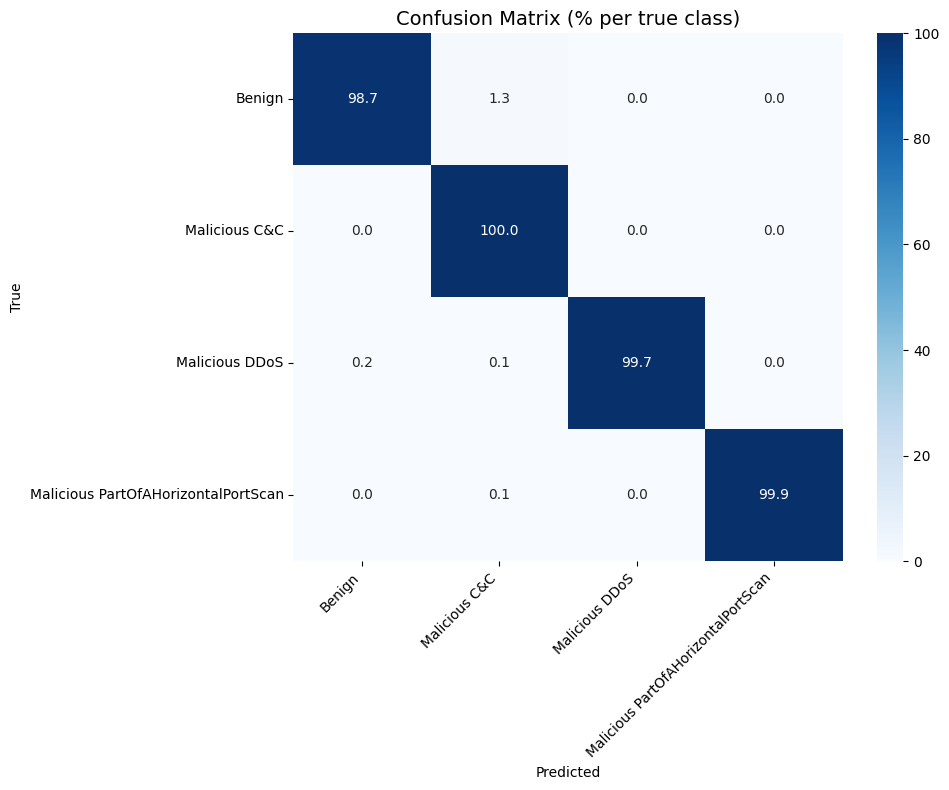

In [37]:
# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_pct,
    annot=True, fmt='.1f', cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)
plt.title('Confusion Matrix (% per true class)', fontsize=14)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('/content/confusion_matrix.png', dpi=150)
plt.show()

In [38]:
# ── Step 11b — Inference Latency Measurement ─────────────────────────────────
# Required for real-time IDS claims; target: <5ms/window GPU, <50ms CPU
import time

model.eval()
latency_runs = 1000

# ── Single-sample latency (worst case / per-window) ──────────────────────────
sample_seq = torch.tensor(X_seq_test[:1],   dtype=torch.float32).to(device)
sample_sp  = torch.tensor(X_sp_test[:1],    dtype=torch.float32).to(device)

with torch.no_grad():
    for _ in range(50):   # warm-up
        _, _, _ = model(sample_seq, sample_sp)  # FIX 1a: 3-tuple

times_single = []
with torch.no_grad():
    for _ in range(latency_runs):
        t0 = time.perf_counter()
        model(sample_seq, sample_sp)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        times_single.append((time.perf_counter() - t0) * 1000)

times_single = np.array(times_single)
print(f'\n⏱  Single-window latency ({latency_runs} runs, batch=1, device={device}):')
print(f'   Mean : {times_single.mean():.3f} ms  |  Std: {times_single.std():.3f} ms')
print(f'   P50  : {np.percentile(times_single, 50):.3f} ms  |  P95: {np.percentile(times_single, 95):.3f} ms  |  P99: {np.percentile(times_single, 99):.3f} ms')

# ── Batch throughput (batch=512, realistic deployment) ────────────────────────
batch_size = min(512, len(X_seq_test))
batch_seq  = torch.tensor(X_seq_test[:batch_size], dtype=torch.float32).to(device)
batch_sp   = torch.tensor(X_sp_test[:batch_size],  dtype=torch.float32).to(device)

with torch.no_grad():
    for _ in range(10):   # warm-up
        _, _, _ = model(batch_seq, batch_sp)  # FIX 1a: 3-tuple

times_batch = []
with torch.no_grad():
    for _ in range(200):
        t0 = time.perf_counter()
        model(batch_seq, batch_sp)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        times_batch.append((time.perf_counter() - t0) * 1000)

times_batch = np.array(times_batch)
throughput  = (batch_size * SEQ_LEN) / (times_batch.mean() / 1000)
print(f'\n⏱  Batch throughput (batch={batch_size}, device={device}):')
print(f'   Batch latency : {times_batch.mean():.3f} ms  |  Std: {times_batch.std():.3f} ms')
print(f'   Throughput    : {throughput:,.0f} flows/sec  ({SEQ_LEN} flows/window × {batch_size} windows/batch)')



⏱  Single-window latency (1000 runs, batch=1, device=cuda):
   Mean : 2.206 ms  |  Std: 1.765 ms
   P50  : 1.890 ms  |  P95: 3.351 ms  |  P99: 3.914 ms

⏱  Batch throughput (batch=512, device=cuda):
   Batch latency : 10.056 ms  |  Std: 6.617 ms
   Throughput    : 814,633 flows/sec  (16 flows/window × 512 windows/batch)


## 🎯 Step 12 — Attention Visualization (Paper Figure)

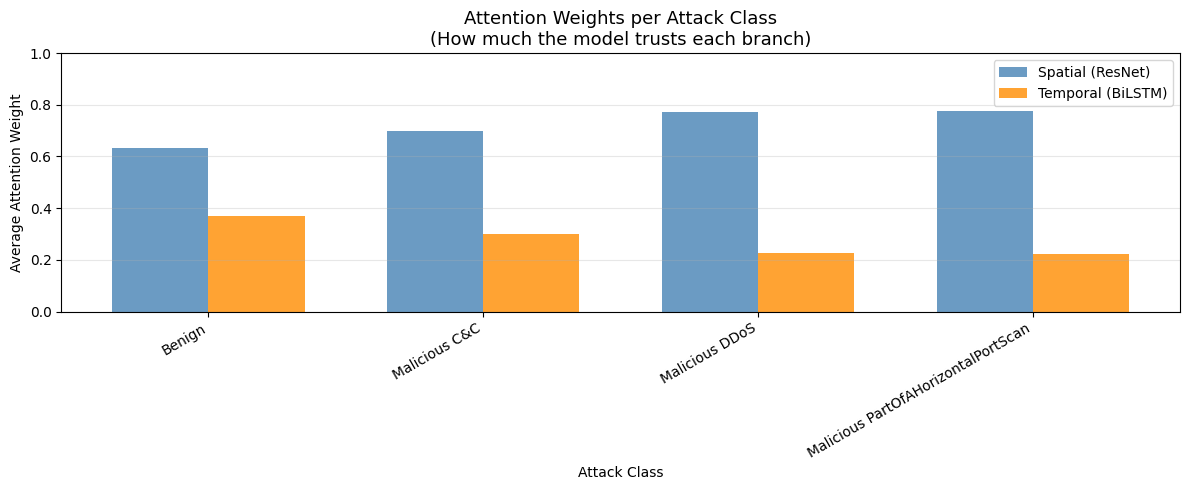


📊 Attention analysis:
  Benign               → dominant: Spatial (0.63 vs 0.37)
  Malicious C&C        → dominant: Spatial (0.70 vs 0.30)
  Malicious DDoS       → dominant: Spatial (0.77 vs 0.23)
  Malicious PartOfAHorizontalPortScan → dominant: Spatial (0.78 vs 0.22)


In [39]:
# Show how attention weights differ per attack class
# This is a KEY figure for your research paper!

attn_by_class = {}
for cls_idx in range(num_classes):
    cls_name = le.classes_[cls_idx]
    mask = (all_labels == cls_idx)
    if mask.sum() > 0:
        # NOTE: attn_weights = stack([t_feat.norm, s_feat.norm], dim=1)
        # so index 0 = temporal, index 1 = spatial
        attn_by_class[cls_name] = {
            'temporal': all_attn[mask, 0].mean(),
            'spatial':  all_attn[mask, 1].mean()
        }

# Plot
class_names = list(attn_by_class.keys())
spatial_w   = [attn_by_class[c]['spatial']  for c in class_names]
temporal_w  = [attn_by_class[c]['temporal'] for c in class_names]

x = np.arange(len(class_names))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 5))
bars1 = ax.bar(x - width/2, spatial_w,  width, label='Spatial (ResNet)', color='steelblue',  alpha=0.8)
bars2 = ax.bar(x + width/2, temporal_w, width, label='Temporal (BiLSTM)', color='darkorange', alpha=0.8)

ax.set_xlabel('Attack Class')
ax.set_ylabel('Average Attention Weight')
ax.set_title('Attention Weights per Attack Class\n(How much the model trusts each branch)', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=30, ha='right')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('/content/attention_weights.png', dpi=150)
plt.show()

print('\n📊 Attention analysis:')
for cls, vals in attn_by_class.items():
    dominant = 'Spatial' if vals['spatial'] > vals['temporal'] else 'Temporal'
    print(f'  {cls:20s} → dominant: {dominant} ({vals["spatial"]:.2f} vs {vals["temporal"]:.2f})')

Spatial dim: 10 | Feature names: 10 ✅
✅ SHAP computed! Shape per class: (50, 4, 10)


/tmp/ipykernel_575/2962656408.py:79: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
/tmp/ipykernel_575/2962656408.py:79: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
/tmp/ipykernel_575/2962656408.py:79: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
/tmp/ipykernel_575/2962656408.py:79: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no

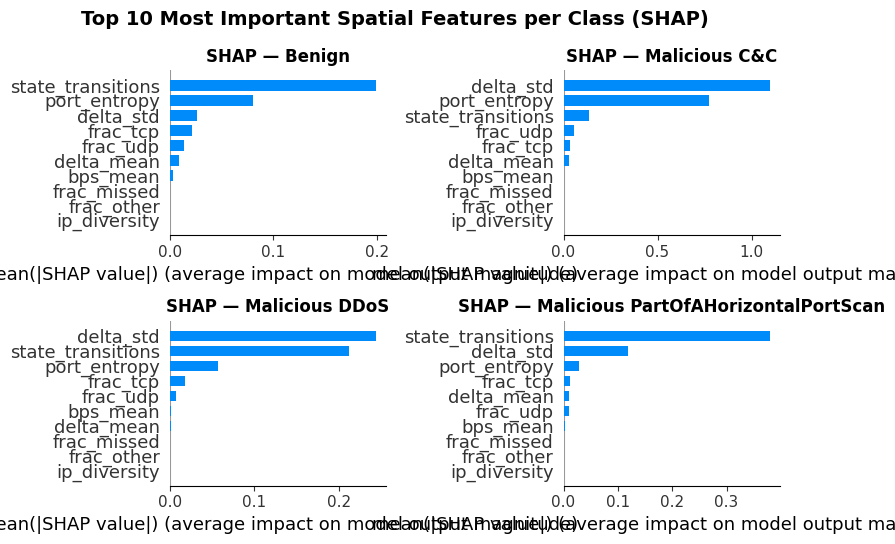

✅ SHAP summary plot saved


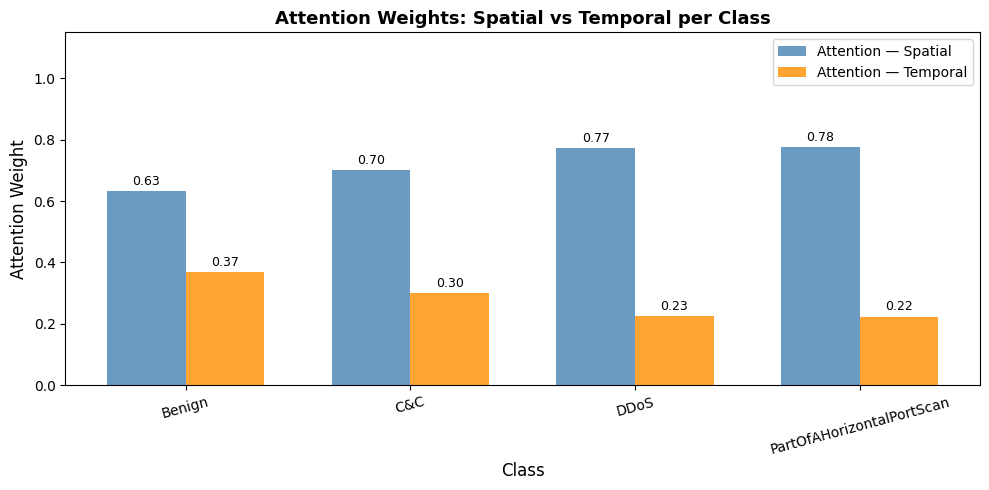

✅ Attention vs SHAP comparison plot saved
Top 5 Most Important Features per Class (SHAP):
───────────────────────────────────────────────────────
Benign:
    1. state_transitions                   SHAP=0.1994
    2. port_entropy                        SHAP=0.0805
    3. delta_std                           SHAP=0.0261
    4. frac_tcp                            SHAP=0.0212
    5. frac_udp                            SHAP=0.0136
Malicious C&C:
    1. delta_std                           SHAP=1.0968
    2. port_entropy                        SHAP=0.7716
    3. state_transitions                   SHAP=0.1344
    4. frac_udp                            SHAP=0.0546
    5. frac_tcp                            SHAP=0.0338
Malicious DDoS:
    1. delta_std                           SHAP=0.2441
    2. state_transitions                   SHAP=0.2125
    3. port_entropy                        SHAP=0.0572
    4. frac_tcp                            SHAP=0.0179
    5. frac_udp                            SH

In [46]:
# ── Step 12b — SHAP Explainability + Attention Comparison ────────────────────
!pip install -q shap

import shap
import matplotlib.pyplot as plt
import numpy as np

# ── Wrapper: spatial input only ───────────────────────────────────────────────
class SpatialOnlyWrapper(torch.nn.Module):
    def forward(self, x_sp):
        batch_size = x_sp.shape[0]
        x_seq_dummy = torch.zeros(batch_size, SEQ_LEN, num_features).to(device)
        logits, _, _ = model(x_seq_dummy, x_sp.to(device))  # FIX 1a: unpack 3-tuple
        return logits

spatial_wrapper = SpatialOnlyWrapper().to(device)
spatial_wrapper.eval()

# ── Use X_sp_test directly (already StandardScaler-transformed in Step 4) ────
# FIX: Previously collected x_sp from DataLoader batches into test_sp_all.
# That is equivalent to X_sp_test since the loader wraps the same array,
# but using X_sp_test directly is explicit, avoids batch-order shuffling,
# and confirms we are always passing scaled data to SHAP — consistent with
# the scaled inputs the model received during training and evaluation.
test_sp_shap    = X_sp_test          # shape (n_test, 10) — already scaled
test_labels_all = y_test             # shape (n_test,)   — aligned with X_sp_test

# ── Spatial feature names — FIX-SHAP ─────────────────────────────────────────
# Hard-coded 10 non-overlapping spatial feature names (Section VII / Table I).
feat_names = [
    'ip_diversity',       # unique dst IPs / window length
    'port_entropy',       # entropy of resp_pkts distribution
    'delta_mean',         # mean inter-flow time delta
    'delta_std',          # std inter-flow time delta
    'state_transitions',  # conn-state change count across window
    'frac_tcp',           # fraction of flows with proto=tcp
    'frac_udp',           # fraction of flows with proto=udp
    'frac_other',         # fraction of flows with proto=icmp/other
    'frac_missed',        # fraction of flows with missed_bytes > 0
    'bps_mean',           # mean bytes-per-sec across window
]
n_sp = test_sp_shap.shape[1]
assert len(feat_names) == n_sp, (
    f"Spatial dim mismatch: X_sp_test has {n_sp} features "
    f"but feat_names has {len(feat_names)}. Check build_windows in Step 4."
)
print(f"Spatial dim: {n_sp} | Feature names: {len(feat_names)} ✅")

# ── Sample background (100) and test points (50) — both from scaled X_sp_test ─
rng_shap = np.random.default_rng(42)
bg_idx   = rng_shap.choice(len(test_sp_shap), 100, replace=False)
test_idx = rng_shap.choice(len(test_sp_shap), 50,  replace=False)

background  = torch.tensor(test_sp_shap[bg_idx],   dtype=torch.float32).to(device)
test_sample = torch.tensor(test_sp_shap[test_idx],  dtype=torch.float32).to(device)

# ── SHAP GradientExplainer ────────────────────────────────────────────────────
explainer       = shap.GradientExplainer(spatial_wrapper, background)
shap_values_raw = explainer.shap_values(test_sample)

# GradientExplainer returns (features, samples) — transpose if needed
if shap_values_raw[0].shape[0] != len(test_idx):
    shap_values = [sv.T for sv in shap_values_raw]
else:
    shap_values = shap_values_raw

print(f'✅ SHAP computed! Shape per class: {np.array(shap_values).shape}')

mean_shap = [np.abs(shap_values[c]).mean(axis=0) for c in range(num_classes)]

# ── Plot 1: SHAP bar summary per class ───────────────────────────────────────
n_cols = min(num_classes, 2)
n_rows = (num_classes + 1) // 2
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 6 * n_rows))
axes = np.array(axes).flatten()

for cls_idx, cls_name in enumerate(le.classes_):
    plt.sca(axes[cls_idx])
    shap.summary_plot(
        shap_values[cls_idx],
        test_sp_shap[test_idx],   # scaled data — consistent with model inputs
        feature_names=feat_names,
        max_display=10,
        show=False,
        plot_type='bar'
    )
    axes[cls_idx].set_title(f'SHAP — {cls_name}', fontsize=12, fontweight='bold')

# Hide unused subplots
for i in range(num_classes, len(axes)):
    axes[i].set_visible(False)

plt.suptitle('Top 10 Most Important Spatial Features per Class (SHAP)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ SHAP summary plot saved')

# ── Plot 2: Attention weight comparison ──────────────────────────────────────
attn_by_class = {}
for cls_idx in range(num_classes):
    mask = (test_labels_all == cls_idx)
    if mask.sum() > 0:
        attn_by_class[cls_idx] = all_attn[mask].mean(axis=0)

fig, ax = plt.subplots(figsize=(10, 5))
x     = np.arange(num_classes)
width = 0.35

# attn_weights = stack([t_feat.norm, s_feat.norm]) → index 0=temporal, 1=spatial
temporal_attn   = [attn_by_class[c][0] for c in range(num_classes) if c in attn_by_class]
spatial_attn    = [attn_by_class[c][1] for c in range(num_classes) if c in attn_by_class]
present_classes = [le.classes_[c] for c in range(num_classes) if c in attn_by_class]
x = np.arange(len(present_classes))

bars1 = ax.bar(x - width/2, spatial_attn,  width, label='Attention — Spatial',  color='steelblue',  alpha=0.8)
bars2 = ax.bar(x + width/2, temporal_attn, width, label='Attention — Temporal', color='darkorange', alpha=0.8)

ax.set_xlabel('Class', fontsize=12)
ax.set_ylabel('Attention Weight', fontsize=12)
ax.set_title('Attention Weights: Spatial vs Temporal per Class', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([c.replace('Malicious ', '') for c in present_classes], rotation=15)
ax.legend()
ax.set_ylim(0, 1.15)

for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{bar.get_height():.2f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('/content/attention_vs_shap.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Attention vs SHAP comparison plot saved')

# ── Top 5 SHAP features per class ────────────────────────────────────────────
print('Top 5 Most Important Features per Class (SHAP):')
print('─' * 55)
for cls_idx, cls_name in enumerate(le.classes_):
    top5_idx = np.abs(mean_shap[cls_idx]).argsort()[::-1][:5]
    print(f'{cls_name}:')
    for rank, fi in enumerate(top5_idx):
        print(f'    {rank+1}. {feat_names[fi]:35s} SHAP={mean_shap[cls_idx][fi]:.4f}')


## 💾 Step 13 — Save Everything

In [47]:
import pickle

torch.save(model.state_dict(), '/content/hybrid_attention_model.pth')

with open('/content/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
with open('/content/sp_scaler.pkl', 'wb') as f:
    pickle.dump(sp_scaler, f)
with open('/content/label_encoder.pkl', 'wb') as f:
    pickle.dump(le, f)

# Fix attn_by_class format
attn_by_class_clean = {}
for cls_idx in range(num_classes):
    cls_name = le.classes_[cls_idx]
    mask = (all_labels == cls_idx)
    if mask.sum() > 0:
        attn_by_class_clean[cls_name] = {
            # attn index 0 = temporal, index 1 = spatial (matches forward() stack order)
            'temporal': float(all_attn[mask, 0].mean()),
            'spatial':  float(all_attn[mask, 1].mean()),
        }

results = {
    'test_accuracy':      float(test_acc),
    'test_f1_weighted':   float(test_f1),
    'num_classes':        num_classes,
    'class_names':        list(le.classes_),
    'num_features':       int(num_features),
    'total_params':       total_params,
    'attention_by_class': attn_by_class_clean
}

with open('/content/results.json', 'w') as f:
    json.dump(results, f, indent=2)

print('✅ Saved all outputs to /content/')

✅ Saved all outputs to /content/


## 📝 Step 14 — Results Summary

In [48]:
print('=' * 55)
print('  HYBRID ATTENTION MODEL — FINAL RESULTS')
print('=' * 55)
print(f'  Architecture : Spatial-MLP + Temporal-BiLSTM + Attention Fusion')
print(f'  Dataset      : CTU IoT Network Traffic')
print(f'  Classes      : {num_classes} ({list(le.classes_)})')
print(f'  Parameters   : {total_params:,}')
print('─' * 55)
print(f'  Test Accuracy : {test_acc*100:.2f}%')
print(f'  Weighted F1   : {test_f1*100:.2f}%')
print('─' * 55)
print('  Attention Analysis:')
for cls, vals in attn_by_class_clean.items():
    dominant = 'Spatial' if vals['spatial'] > vals['temporal'] else 'Temporal'
    print(f'  {cls:40s} → {dominant} ({vals["spatial"]:.2f} vs {vals["temporal"]:.2f})')
print('=' * 55)

  HYBRID ATTENTION MODEL — FINAL RESULTS
  Architecture : Spatial-MLP + Temporal-BiLSTM + Attention Fusion
  Dataset      : CTU IoT Network Traffic
  Classes      : 4 (['Benign', 'Malicious C&C', 'Malicious DDoS', 'Malicious PartOfAHorizontalPortScan'])
  Parameters   : 1,145,865
───────────────────────────────────────────────────────
  Test Accuracy : 99.36%
  Weighted F1   : 99.40%
───────────────────────────────────────────────────────
  Attention Analysis:
  Benign                                   → Spatial (0.63 vs 0.37)
  Malicious C&C                            → Spatial (0.70 vs 0.30)
  Malicious DDoS                           → Spatial (0.77 vs 0.23)
  Malicious PartOfAHorizontalPortScan      → Spatial (0.78 vs 0.22)
